# Maintain Velocity Sweep: Normalized Return vs Speed

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [14]:
# Load the summary CSV
csv_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/sweep/maintain_velocity_sweep_summary.csv"
)
df_wide = pd.read_csv(csv_path)
df_wide.head()

,speed,decoder_only_seed0,decoder_only_seed1,decoder_only_seed2,decoder_only_seed3,prior_decoder_seed0,prior_decoder_seed1,prior_decoder_seed2,prior_decoder_seed3,scratch_seed0,scratch_seed1,scratch_seed2,scratch_seed3
0,0.1,983.764160,986.212280,984.456726,989.214844,979.656006,979.871216,984.042175,983.718140,968.253540,950.834106,973.950806,973.991821
1,0.3,989.101990,989.911316,980.945923,923.149231,990.350586,988.916931,987.168640,990.098389,919.770569,964.546204,959.902832,959.671326
2,0.5,924.553345,959.470886,954.255615,961.608765,988.386780,988.810242,988.467285,990.139709,961.717651,959.683411,969.424988,965.708252
3,0.7,790.011719,791.707886,824.016724,784.310791,987.547791,986.866577,989.680969,983.512329,945.006165,954.117310,963.688538,951.017334
4,1.0,556.213135,558.523560,564.565247,570.421631,974.591064,974.497986,984.168335,983.220642,909.194031,894.834595,951.061035,911.044067


In [15]:
# Melt into long format for seaborn
# Columns are: speed, decoder_only_seed0, ..., prior_decoder_seed0, ..., scratch_seed0, ...
id_vars = ["speed"]
value_vars = [c for c in df_wide.columns if c != "speed"]

df_long = df_wide.melt(
    id_vars=id_vars, value_vars=value_vars, var_name="run", value_name="reward"
)

# Parse training mode and seed from the run column
df_long["mode"] = df_long["run"].str.replace(r"_seed\d+$", "", regex=True)
df_long["seed"] = df_long["run"].str.extract(r"seed(\d+)").astype(int)

# Normalize reward by dividing by 1000
df_long["normalized_return"] = df_long["reward"] / 1000

# Map mode names to legend labels
mode_labels = {
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
    "scratch": "Scratch",
}
df_long["Training Mode"] = df_long["mode"].map(mode_labels)

df_long.head()

,speed,run,reward,mode,seed,normalized_return,Training Mode
0,0.1,decoder_only_seed0,983.764160,decoder_only,0,0.983764,Decoder-Only
1,0.3,decoder_only_seed0,989.101990,decoder_only,0,0.989102,Decoder-Only
2,0.5,decoder_only_seed0,924.553345,decoder_only,0,0.924553,Decoder-Only
3,0.7,decoder_only_seed0,790.011719,decoder_only,0,0.790012,Decoder-Only
4,1.0,decoder_only_seed0,556.213135,decoder_only,0,0.556213,Decoder-Only


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/maintain_velocity_sweep.[pdf|svg|png]


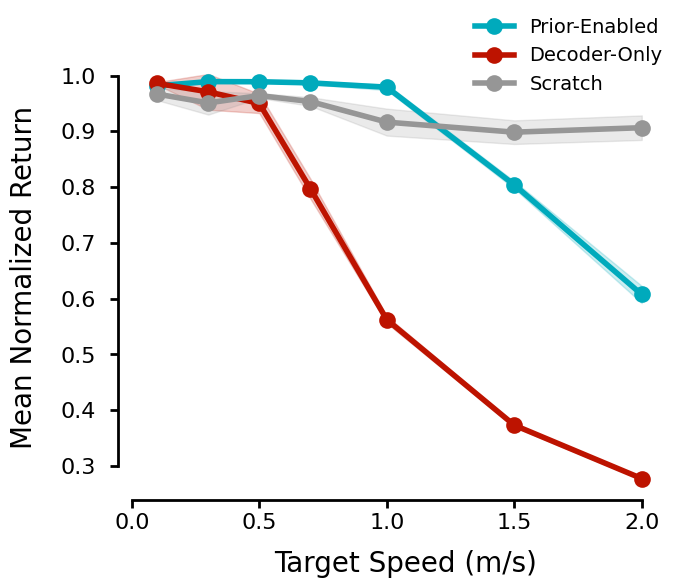

In [17]:
# Define colors for each training mode
palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

# Plot order
hue_order = ["Prior-Enabled", "Decoder-Only", "Scratch"]

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_name = "maintain_velocity_sweep"

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=df_long,
    x="speed",
    y="normalized_return",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax,
)

ax.set_xlim(0, 2.15)

ax.set_xlabel("Target Speed (m/s)", fontsize=20, labelpad=12)
ax.set_ylabel("Mean Normalized Return", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

# Remove top and right spines
sns.despine(ax=ax)

# Trim spines to data range
xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

# Shift y-axis spine to the left
ax.spines["left"].set_position(("outward", 10))

# Thicken remaining spines
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# Style legend - top right, shifted upwards
ax.legend(fontsize=14, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.12))

plt.tight_layout()

# Save
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()